# Results walkthrough

A guided tour of the results of the facial skin disease classifier. **Nothing is trained here**: the notebook only reads the files that the project already produced (`outputs/` and `docs/`), so it runs in a few seconds and its outputs can be read directly on GitHub.

To reproduce the numbers from the checkpoint, run `python src/evaluate.py`.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image

ROOT = Path("..")
OUT = ROOT / "outputs"
DOCS = ROOT / "docs"
CLASSES = ["Acne", "Actinic Keratosis", "Basal Cell Carcinoma", "Eczema", "Rosacea"]

def show(path, title=None, width=11):
    img = Image.open(path)
    plt.figure(figsize=(width, width * img.height / img.width))
    plt.imshow(img); plt.axis("off")
    if title: plt.title(title)
    plt.show()

## 1. Overall results on the test set

In [2]:
metrics = json.loads((OUT / "test_metrics.json").read_text())
overall = pd.DataFrame(metrics).loc[["images", "loss", "accuracy", "macro_f1"], ["val", "test"]]
print("Validation vs test (the test set is the number to trust):")
overall

Validation vs test (the test set is the number to trust):


,val,test
images,65.0000,185.000
loss,0.4786,0.536
accuracy,0.7846,0.800
macro_f1,0.7850,0.797


In [3]:
per_class = pd.DataFrame(metrics["test_per_class"]).T
per_class.style.format({"precision": "{:.2f}", "recall": "{:.2f}", "f1-score": "{:.2f}"}).background_gradient(
    subset=["recall"], cmap="Blues")

,precision,recall,f1-score,support
Acne,0.84,0.86,0.85,37.000000
Actinic Keratosis,0.89,0.62,0.73,37.000000
Basal Cell Carcinoma,0.71,0.97,0.82,37.000000
Eczema,0.83,0.78,0.81,37.000000
Rosacea,0.80,0.76,0.78,37.000000


Actinic Keratosis has the lowest recall and Basal Cell Carcinoma the lowest precision: the model tends to answer "BCC" when it is unsure.

## 2. Where the errors are

In [4]:
pred = pd.read_csv(OUT / "test_predictions.csv")
print(f"{(pred.correct == 0).sum()} wrong out of {len(pred)} test images ({pred.correct.mean():.1%} correct)")
cm = pd.crosstab(pred["true"], pred["predicted"]).reindex(index=CLASSES, columns=CLASSES, fill_value=0)
cm

37 wrong out of 185 test images (80.0% correct)


predicted,Acne,Actinic Keratosis,Basal Cell Carcinoma,Eczema,Rosacea
true,,,,,
Acne,32,0,2,3,0
Actinic Keratosis,1,23,7,1,5
Basal Cell Carcinoma,0,0,36,1,0
Eczema,1,3,2,29,2
Rosacea,4,0,4,1,28


In [5]:
errors = (pred[pred.correct == 0].groupby(["true", "predicted"]).size()
          .sort_values(ascending=False).rename("images").reset_index())
errors.head(8)

,true,predicted,images
0,Actinic Keratosis,Basal Cell Carcinoma,7
1,Actinic Keratosis,Rosacea,5
2,Rosacea,Acne,4
3,Rosacea,Basal Cell Carcinoma,4
4,Acne,Eczema,3
5,Eczema,Actinic Keratosis,3
6,Acne,Basal Cell Carcinoma,2
7,Eczema,Basal Cell Carcinoma,2


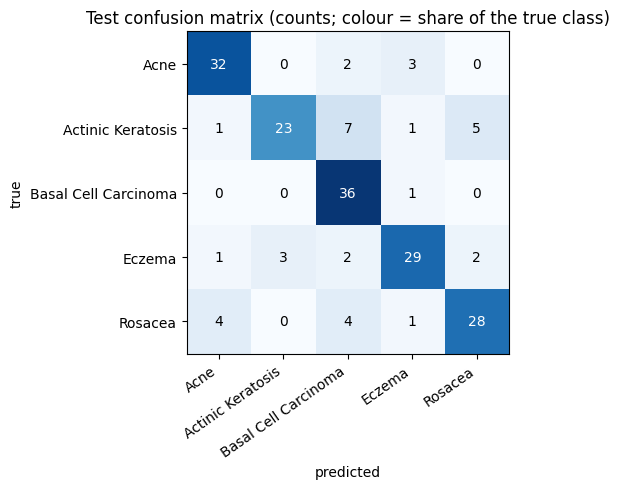

In [6]:
fig, ax = plt.subplots(figsize=(6.5, 5))
rate = cm.div(cm.sum(axis=1), axis=0)
im = ax.imshow(rate, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(5), CLASSES, rotation=35, ha="right"); ax.set_yticks(range(5), CLASSES)
for i in range(5):
    for j in range(5):
        ax.text(j, i, f"{cm.iloc[i, j]}", ha="center", va="center", color="white" if rate.iloc[i, j] > .5 else "black")
ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title("Test confusion matrix (counts; colour = share of the true class)")
plt.tight_layout(); plt.show()

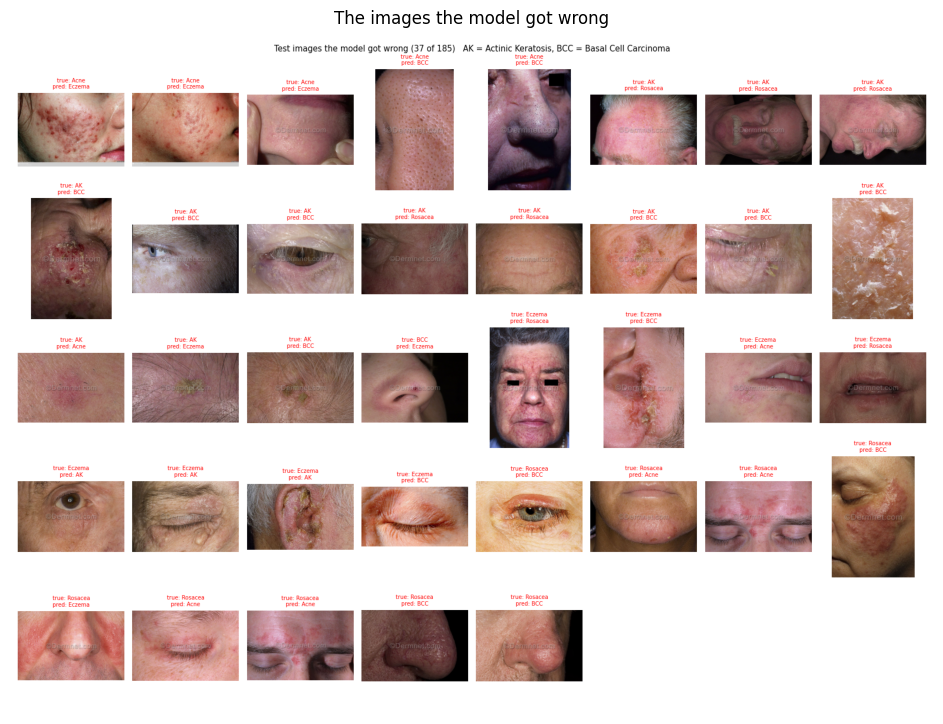

In [7]:
show(DOCS / "error_gallery.png", "The images the model got wrong", width=12)

## 3. Training behaviour

In [8]:
rows = []
for line in (OUT / "training_log.csv").read_text().splitlines():
    parts = line.split(",")
    if parts and parts[0].isdigit():
        rows.append([float(x) for x in parts[:6]])
log = pd.DataFrame(rows, columns=["epoch", "train_loss", "train_acc", "val_loss", "val_acc", "val_macro_f1"]).set_index("epoch")
best = log.val_macro_f1.idxmax()
print(f"best epoch by validation macro-F1: {int(best)}  (val macro-F1 {log.val_macro_f1.max():.3f})")
log.round(3)

best epoch by validation macro-F1: 5  (val macro-F1 0.816)


,train_loss,train_acc,val_loss,val_acc,val_macro_f1
epoch,,,,,
1.0,1.212,0.531,0.875,0.708,0.706
2.0,0.531,0.800,0.747,0.708,0.700
3.0,0.288,0.920,0.595,0.754,0.751
4.0,0.229,0.936,0.475,0.800,0.795
5.0,0.089,0.987,0.481,0.815,0.816
6.0,0.099,0.979,0.519,0.800,0.803
7.0,0.066,0.989,0.614,0.738,0.740
8.0,0.042,0.995,0.515,0.754,0.753
9.0,0.051,0.995,0.503,0.769,0.766


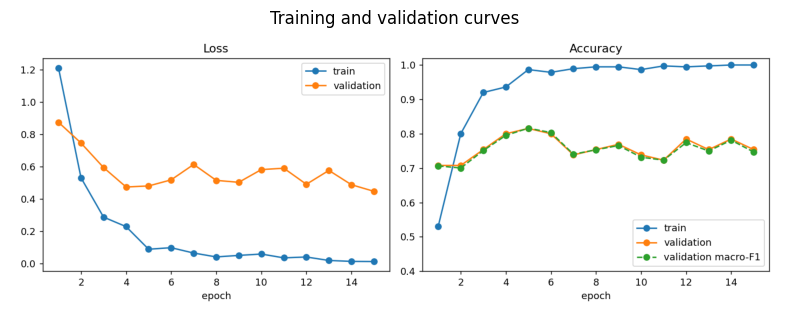

In [9]:
show(DOCS / "training_curves.png", "Training and validation curves", width=10)

The training accuracy reaches 100% while the validation accuracy stays around 71-82%: the model overfits the small training set.

## 4. Explanations (Grad-CAM)

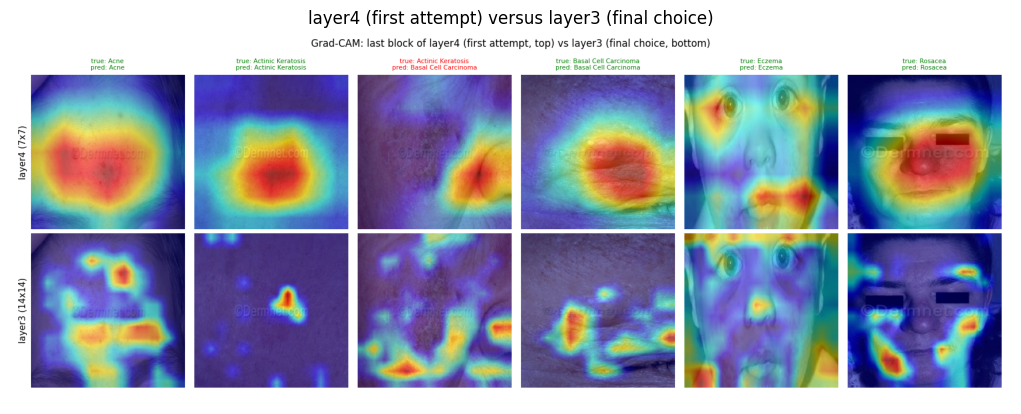

In [10]:
show(DOCS / "gradcam_layer_comparison.png", "layer4 (first attempt) versus layer3 (final choice)", width=13)

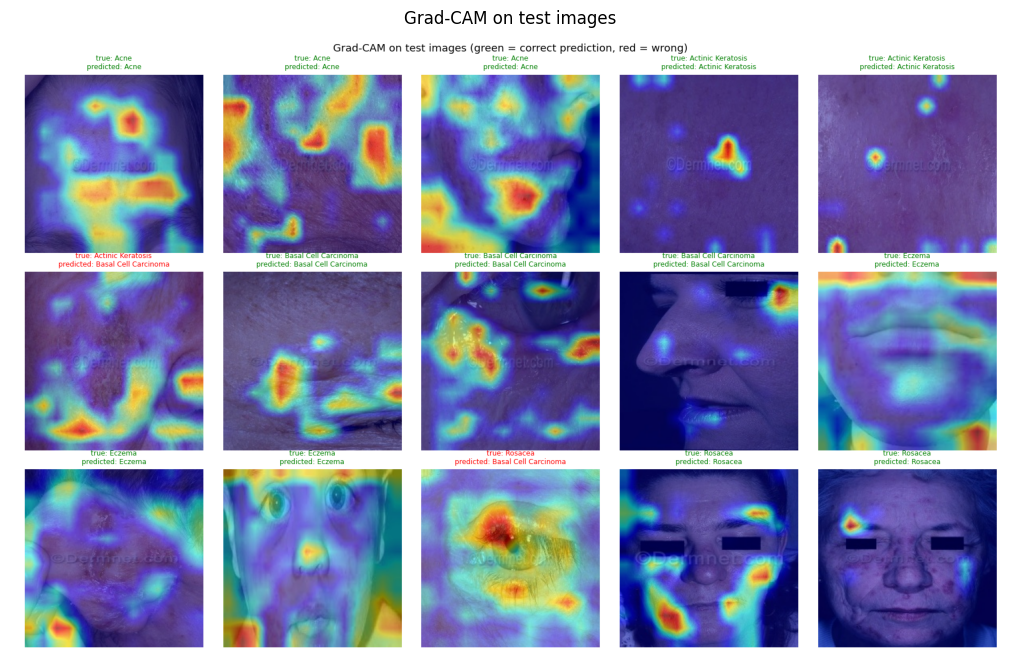

In [11]:
show(DOCS / "gradcam_examples.png", "Grad-CAM on test images", width=13)

`layer3` gives finer maps that follow individual lesions; `layer4` only produces one coarse blob. Some maps, especially in wrong predictions, are still diffuse or fall on the background.